# Day 5: Exploratory Data Analysis (EDA) and Data Quality Review

**Project:** IPL Player Performance Analytics and Prediction Using Machine Learning and Deep Learning

## Objective
Explore the Day 3 player-match datasets and Day 4 next-match feature tables. Summarize coverage, distributions, missingness, outliers, relationships, and target availability before model training.

## Important
- Run this notebook from the project root or keep the project folder structure intact.
- This notebook does not train models.
- It does not silently remove outliers or impute missing values.
- Treat charts and summaries as descriptive, not as proof of causation.
- If a file or required column is missing, stop and inspect the actual saved output instead of fabricating a replacement.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the project root from the notebook's current folder or its parents.
current_dir = Path.cwd().resolve()
candidates = [current_dir, *current_dir.parents]

def is_project_root(candidate: Path) -> bool:
    expected = [
        candidate / "data" / "processed" / "batting_player_match.csv",
        candidate / "data" / "processed" / "bowling_player_match.csv",
        candidate / "data" / "processed" / "batting_next_match_features.csv",
        candidate / "data" / "processed" / "bowling_next_match_features.csv",
    ]
    return (
        (candidate / "data").is_dir()
        and ((candidate / "notebooks").is_dir() or any(p.is_file() for p in expected))
    )

PROJECT_ROOT = next((p for p in candidates if is_project_root(p)), None)
if PROJECT_ROOT is None:
    PROJECT_ROOT = Path(r"D:\Git\Personal\ipl-player-performance")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
DOCS_DIR = PROJECT_ROOT / "docs"
REPORTS_DIR = PROJECT_ROOT / "reports" / "day5"
DOCS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Current working directory:", current_dir)
print("Project root:", PROJECT_ROOT)
print("Processed directory:", PROCESSED_DIR)


Current working directory: D:\Git\Personal\ipl-player-performance\notebooks
Project root: D:\Git\Personal\ipl-player-performance
Processed directory: D:\Git\Personal\ipl-player-performance\data\processed


In [2]:
def load_csv_if_exists(path: Path) -> pd.DataFrame | None:
    if not path.is_file():
        print(f"MISSING: {path}")
        return None
    df = pd.read_csv(path)
    print(f"LOADED: {path.name} | shape={df.shape}")
    return df

batting_path = PROCESSED_DIR / "batting_player_match.csv"
bowling_path = PROCESSED_DIR / "bowling_player_match.csv"
matches_path = PROCESSED_DIR / "match_metadata.csv"
batting_features_path = PROCESSED_DIR / "batting_next_match_features.csv"
bowling_features_path = PROCESSED_DIR / "bowling_next_match_features.csv"

batting = load_csv_if_exists(batting_path)
bowling = load_csv_if_exists(bowling_path)
matches = load_csv_if_exists(matches_path)
batting_features = load_csv_if_exists(batting_features_path)
bowling_features = load_csv_if_exists(bowling_features_path)

if batting is None or bowling is None or matches is None:
    raise FileNotFoundError(
        "One or more Day 3 datasets are missing. Complete/verify Day 3 outputs before EDA."
    )

if batting_features is None or bowling_features is None:
    warnings.warn(
        "Day 4 feature tables are missing. EDA will continue on Day 3 observed-performance "
        "tables, but target analysis will be skipped. Verify Day 4 outputs before modelling."
    )


LOADED: batting_player_match.csv | shape=(18768, 24)
LOADED: bowling_player_match.csv | shape=(14700, 24)
LOADED: match_metadata.csv | shape=(1243, 9)
LOADED: batting_next_match_features.csv | shape=(18030, 49)
LOADED: bowling_next_match_features.csv | shape=(14123, 50)


## 1. Schema and coverage audit

Check column names, row counts, player coverage, match coverage, and date ranges. Do not assume the dataset has columns that were not generated by earlier notebooks.


In [3]:
def coverage_summary(df: pd.DataFrame, name: str) -> dict:
    summary = {
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "unique_matches": df["match_id"].nunique() if "match_id" in df else np.nan,
        "unique_players": df["player_name"].nunique() if "player_name" in df else np.nan,
        "date_min": pd.to_datetime(df["date"], errors="coerce").min() if "date" in df else pd.NaT,
        "date_max": pd.to_datetime(df["date"], errors="coerce").max() if "date" in df else pd.NaT,
    }
    return summary

coverage_rows = [
    coverage_summary(batting, "batting_player_match"),
    coverage_summary(bowling, "bowling_player_match"),
    coverage_summary(matches, "match_metadata"),
]
if batting_features is not None:
    coverage_rows.append(coverage_summary(batting_features, "batting_next_match_features"))
if bowling_features is not None:
    coverage_rows.append(coverage_summary(bowling_features, "bowling_next_match_features"))

coverage_df = pd.DataFrame(coverage_rows)
display(coverage_df)
coverage_df.to_csv(REPORTS_DIR / "coverage_summary.csv", index=False)

print("\nBatting columns:", list(batting.columns))
print("\nBowling columns:", list(bowling.columns))
print("\nMatch metadata columns:", list(matches.columns))


,dataset,rows,columns,unique_matches,unique_players,date_min,date_max
0,batting_player_match,18768,24,1243,738.0,2008-04-18,2026-05-31
1,bowling_player_match,14700,24,1243,577.0,2008-04-18,2026-05-31
2,match_metadata,1243,9,1243,NaN,2008-04-18,2026-05-31
3,batting_next_match_features,18030,49,1240,633.0,2008-04-18,2026-05-29
4,bowling_next_match_features,14123,50,1240,503.0,2008-04-18,2026-05-29



Batting columns: ['match_id', 'date', 'season', 'venue', 'city', 'team_1', 'team_2', 'match_type', 'team', 'opposition', 'player_name', 'player_id', 'player_name_norm', 'team_norm', 'opposition_norm', 'runs', 'balls_faced', 'fours', 'sixes', 'batting_position', 'was_dismissed', 'dismissal_kind', 'innings_count', 'strike_rate']

Bowling columns: ['match_id', 'date', 'season', 'venue', 'city', 'team_1', 'team_2', 'match_type', 'team', 'opposition', 'player_name', 'player_id', 'player_name_norm', 'team_norm', 'opposition_norm', 'legal_balls', 'runs_conceded', 'wickets', 'wides', 'noballs', 'dots', 'innings_count', 'overs', 'economy']

Match metadata columns: ['match_id', 'source_file', 'date', 'season', 'venue', 'city', 'team_1', 'team_2', 'match_type']


## 2. Missing values and duplicate keys

This section reports missingness and potential duplicate player-match keys. It does not drop rows. Investigate the causes before deciding on a cleaning rule.


In [4]:
def missingness_report(df: pd.DataFrame, name: str) -> pd.DataFrame:
    result = pd.DataFrame({
        "column": df.columns,
        "missing_count": [int(df[c].isna().sum()) for c in df.columns],
        "missing_percent": [float(df[c].isna().mean() * 100) for c in df.columns],
        "dtype": [str(df[c].dtype) for c in df.columns],
    }).sort_values(["missing_percent", "missing_count"], ascending=False)
    result.insert(0, "dataset", name)
    return result

missing_reports = [
    missingness_report(batting, "batting"),
    missingness_report(bowling, "bowling"),
    missingness_report(matches, "matches"),
]
if batting_features is not None:
    missing_reports.append(missingness_report(batting_features, "batting_features"))
if bowling_features is not None:
    missing_reports.append(missingness_report(bowling_features, "bowling_features"))

missing_df = pd.concat(missing_reports, ignore_index=True)
display(missing_df.head(40))
missing_df.to_csv(REPORTS_DIR / "missingness_report.csv", index=False)

duplicate_rows = []
for name, df in [("batting", batting), ("bowling", bowling)]:
    keys = [c for c in ["match_id", "player_name"] if c in df.columns]
    if len(keys) == 2:
        duplicate_mask = df.duplicated(keys, keep=False)
        duplicate_rows.append({
            "dataset": name,
            "key_columns": ", ".join(keys),
            "rows_in_duplicate_groups": int(duplicate_mask.sum()),
            "duplicate_groups": int(df.loc[duplicate_mask, keys].drop_duplicates().shape[0]),
        })
duplicate_keys_df = pd.DataFrame(duplicate_rows)
display(duplicate_keys_df)
duplicate_keys_df.to_csv(REPORTS_DIR / "duplicate_key_report.csv", index=False)


,dataset,column,missing_count,missing_percent,dtype
0,batting,match_type,18768,100.000000,float64
1,batting,dismissal_kind,4144,22.080136,str
2,batting,city,746,3.974851,str
3,batting,strike_rate,8,0.042626,float64
4,batting,match_id,0,0.000000,int64
5,batting,date,0,0.000000,str
6,batting,season,0,0.000000,str
7,batting,venue,0,0.000000,str
8,batting,team_1,0,0.000000,str
9,batting,team_2,0,0.000000,str


,dataset,key_columns,rows_in_duplicate_groups,duplicate_groups
0,batting,"match_id, player_name",0,0
1,bowling,"match_id, player_name",0,0


## 3. Numeric distributions and outlier review

Use descriptive statistics and boxplots to identify values that merit review. Extreme cricket performances can be legitimate; this notebook does not automatically remove them.


,dataset,column,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
0,batting,match_id,18768.0,979129.197943,396955.959887,335982.0,335994.000000,548372.000000,1.082642e+06,1.304110e+06,1.527686e+06,1.529306e+06,1.535465e+06
1,batting,match_type,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,batting,runs,18768.0,20.328698,21.685142,0.0,0.000000,4.000000,1.300000e+01,3.000000e+01,6.600000e+01,9.300000e+01,1.750000e+02
3,batting,balls_faced,18768.0,15.165708,13.368298,0.0,1.000000,5.000000,1.100000e+01,2.200000e+01,4.400000e+01,5.600000e+01,7.300000e+01
4,batting,fours,18768.0,1.835411,2.326343,0.0,0.000000,0.000000,1.000000e+00,3.000000e+00,7.000000e+00,1.000000e+01,1.900000e+01
5,batting,sixes,18768.0,0.840740,1.427955,0.0,0.000000,0.000000,0.000000e+00,1.000000e+00,4.000000e+00,7.000000e+00,1.700000e+01
6,batting,batting_position,18768.0,4.606884,2.652214,1.0,1.000000,2.000000,4.000000e+00,7.000000e+00,9.000000e+00,1.100000e+01,1.100000e+01
7,batting,innings_count,18768.0,1.003943,0.062670,1.0,1.000000,1.000000,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00
8,batting,strike_rate,18760.0,115.804277,70.372655,0.0,0.000000,70.000000,1.142857e+02,1.555556e+02,2.312500e+02,3.180993e+02,1.000000e+03
9,bowling,match_id,14700.0,973116.364014,396487.877416,335982.0,335994.000000,548365.000000,1.082632e+06,1.304103e+06,1.527683e+06,1.529305e+06,1.535465e+06


C:\Users\Vinod\AppData\Local\Temp\ipykernel_4540\944167578.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


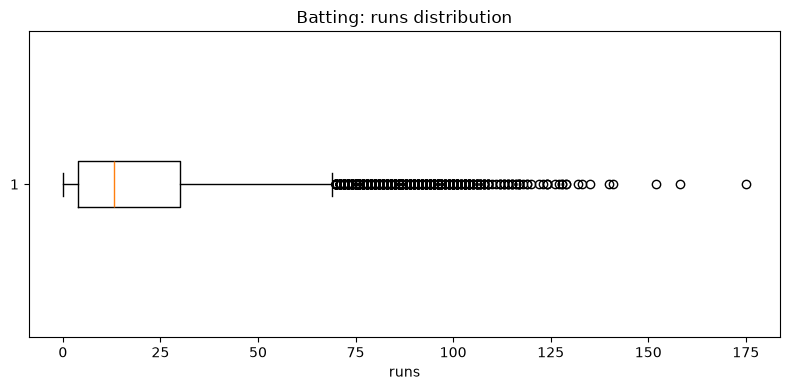

C:\Users\Vinod\AppData\Local\Temp\ipykernel_4540\944167578.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


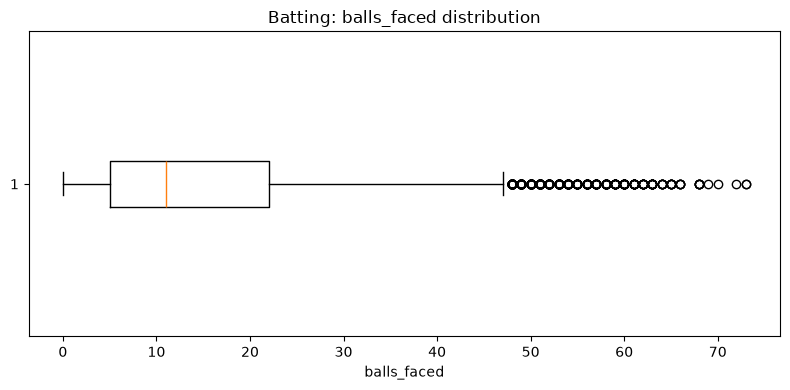

C:\Users\Vinod\AppData\Local\Temp\ipykernel_4540\944167578.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


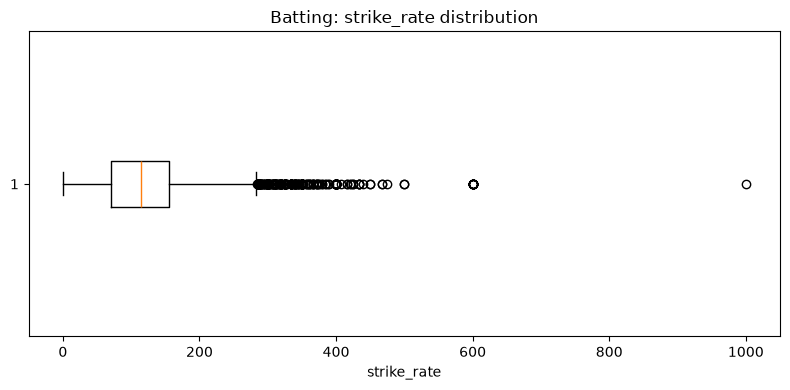

C:\Users\Vinod\AppData\Local\Temp\ipykernel_4540\944167578.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


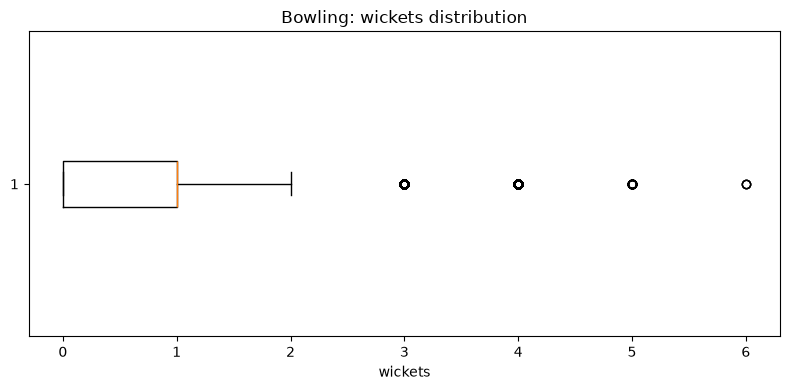

C:\Users\Vinod\AppData\Local\Temp\ipykernel_4540\944167578.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


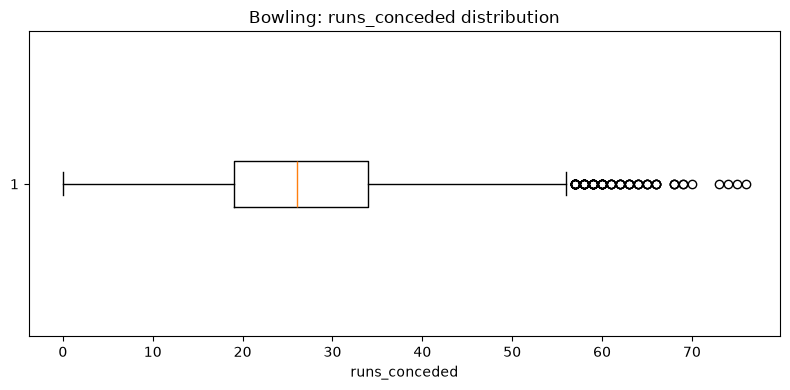

C:\Users\Vinod\AppData\Local\Temp\ipykernel_4540\944167578.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


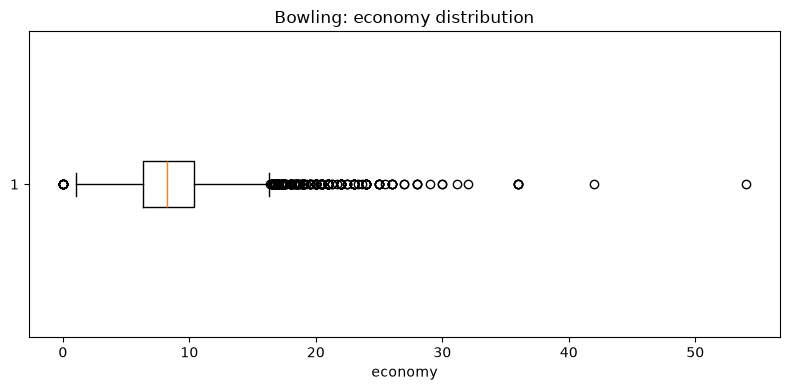

C:\Users\Vinod\AppData\Local\Temp\ipykernel_4540\944167578.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


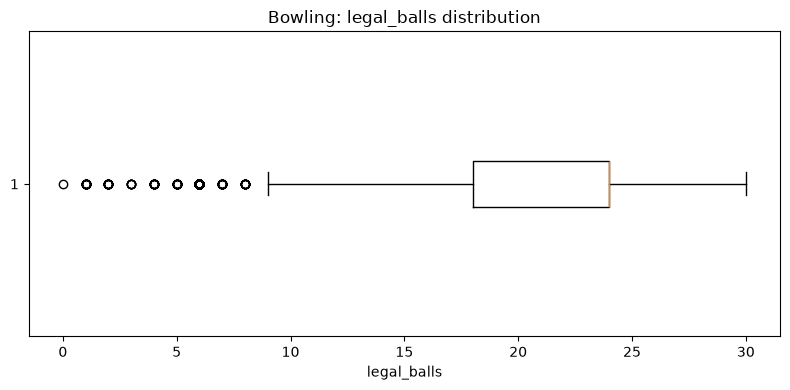

In [5]:
def describe_numeric(df: pd.DataFrame, name: str) -> pd.DataFrame:
    numeric = df.select_dtypes(include=[np.number])
    if numeric.empty:
        return pd.DataFrame()
    desc = numeric.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).T
    desc.insert(0, "dataset", name)
    desc.insert(1, "column", desc.index)
    return desc.reset_index(drop=True)

numeric_reports = [
    describe_numeric(batting, "batting"),
    describe_numeric(bowling, "bowling"),
]
if batting_features is not None:
    numeric_reports.append(describe_numeric(batting_features, "batting_features"))
if bowling_features is not None:
    numeric_reports.append(describe_numeric(bowling_features, "bowling_features"))

numeric_df = pd.concat([x for x in numeric_reports if not x.empty], ignore_index=True)
display(numeric_df.head(50))
numeric_df.to_csv(REPORTS_DIR / "numeric_descriptive_statistics.csv", index=False)

plot_specs = [
    (batting, ["runs", "balls_faced", "strike_rate"], "Batting"),
    (bowling, ["wickets", "runs_conceded", "economy", "legal_balls"], "Bowling"),
]
for df, columns, title in plot_specs:
    available = [c for c in columns if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]
    for col in available:
        values = df[col].dropna()
        if values.empty:
            continue
        plt.figure(figsize=(8, 4))
        plt.boxplot(values, vert=False)
        plt.title(f"{title}: {col} distribution")
        plt.xlabel(col)
        plt.tight_layout()
        plt.show()


## 4. Performance distributions and trends

Review how batting and bowling performance vary across matches and seasons. Seasonal comparisons are shown only when season information exists in the actual data.


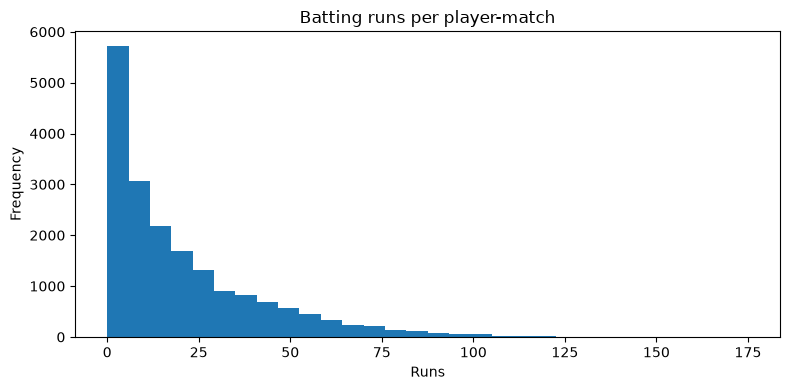

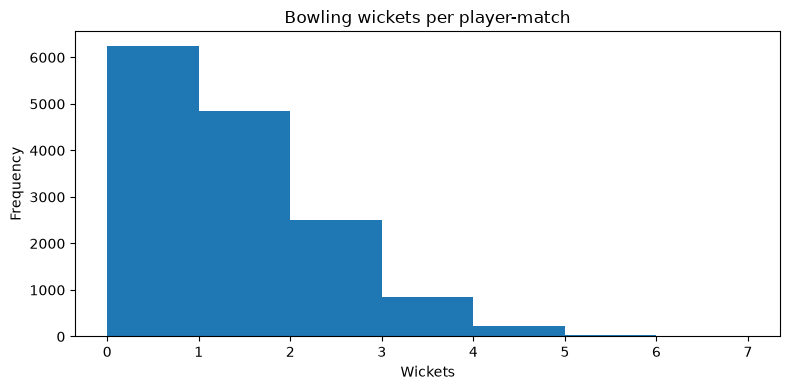

,season,player_match_rows,mean_runs,median_runs,total_runs
0,2007/08,881,19.079455,12.0,16809
1,2009,875,17.572571,10.0,15376
2,2009/10,917,19.360960,13.0,17754
3,2011,1055,18.889100,13.0,19928
4,2012,1108,19.244585,12.0,21323
5,2013,1162,18.491394,12.0,21487
6,2014,873,20.553265,14.0,17943
7,2015,881,19.780931,13.0,17427
8,2016,865,20.765318,12.0,17962
9,2017,898,19.955457,12.0,17920


,season,player_match_rows,mean_wickets,median_wickets,total_wickets
0,2007/08,685,0.881752,1.0,604
1,2009,710,0.876056,1.0,622
2,2009/10,726,0.867769,1.0,630
3,2011,876,0.843607,1.0,739
4,2012,873,0.884307,1.0,772
5,2013,890,0.933708,1.0,831
6,2014,692,0.875723,1.0,606
7,2015,690,0.907246,1.0,626
8,2016,724,0.816298,1.0,591
9,2017,705,0.924823,1.0,652


In [6]:
if "runs" in batting.columns:
    plt.figure(figsize=(8, 4))
    plt.hist(batting["runs"].dropna(), bins=30)
    plt.title("Batting runs per player-match")
    plt.xlabel("Runs")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

if "wickets" in bowling.columns:
    plt.figure(figsize=(8, 4))
    plt.hist(bowling["wickets"].dropna(), bins=range(0, int(bowling["wickets"].max()) + 2))
    plt.title("Bowling wickets per player-match")
    plt.xlabel("Wickets")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

if "season" in batting.columns and "runs" in batting.columns:
    season_batting = batting.groupby("season", dropna=False).agg(
        player_match_rows=("runs", "size"),
        mean_runs=("runs", "mean"),
        median_runs=("runs", "median"),
        total_runs=("runs", "sum"),
    ).reset_index()
    display(season_batting)
    season_batting.to_csv(REPORTS_DIR / "season_batting_summary.csv", index=False)
else:
    print("No season column in batting data; season trend skipped.")

if "season" in bowling.columns and "wickets" in bowling.columns:
    season_bowling = bowling.groupby("season", dropna=False).agg(
        player_match_rows=("wickets", "size"),
        mean_wickets=("wickets", "mean"),
        median_wickets=("wickets", "median"),
        total_wickets=("wickets", "sum"),
    ).reset_index()
    display(season_bowling)
    season_bowling.to_csv(REPORTS_DIR / "season_bowling_summary.csv", index=False)
else:
    print("No season column in bowling data; bowling season trend skipped.")


## 5. Target distributions and target coverage (Day 4 outputs)

Target analysis runs only if the Day 4 feature tables are available and contain the expected targets. Metrics and distributions here are descriptive only.


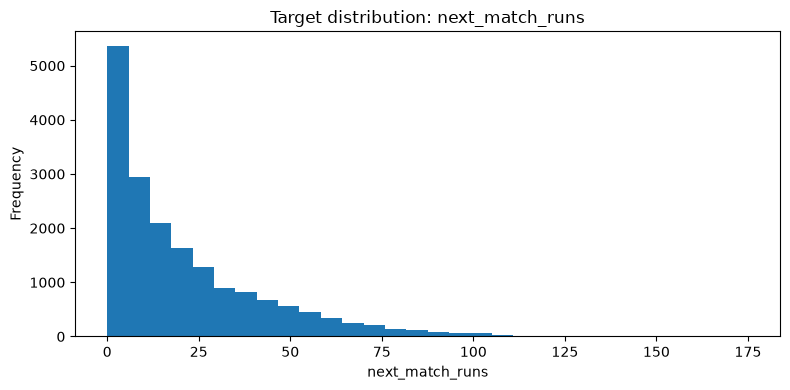

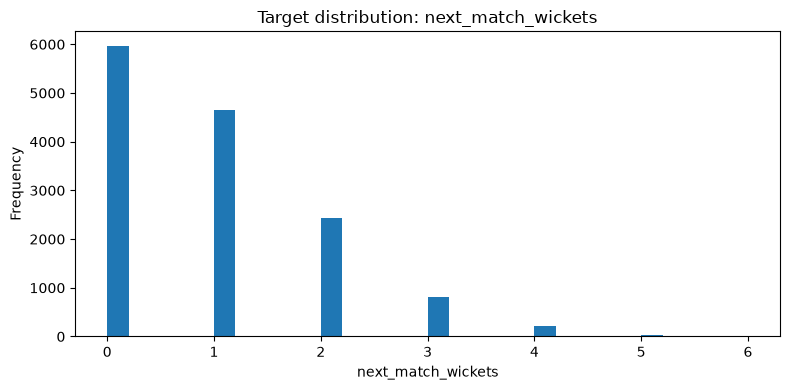

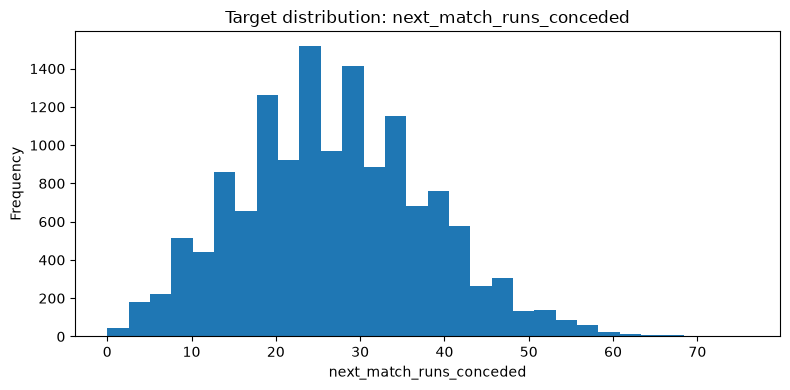

,dataset,target,rows,non_missing,missing,mean,median,std,min,max
0,batting_features,next_match_runs,18030,18030,0,20.704049,13.0,21.830644,0.0,175.0
1,bowling_features,next_match_wickets,14123,14123,0,0.922396,1.0,1.001237,0.0,6.0
2,bowling_features,next_match_runs_conceded,14123,14123,0,26.897260,26.0,11.188855,0.0,76.0


In [7]:
target_summaries = []
for name, df, targets in [
    ("batting_features", batting_features, ["next_match_runs"]),
    ("bowling_features", bowling_features, ["next_match_wickets", "next_match_runs_conceded"]),
]:
    if df is None:
        continue
    for target in targets:
        if target not in df.columns:
            print(f"{name}: target {target!r} is missing; skipped.")
            continue
        s = pd.to_numeric(df[target], errors="coerce")
        target_summaries.append({
            "dataset": name,
            "target": target,
            "rows": int(len(s)),
            "non_missing": int(s.notna().sum()),
            "missing": int(s.isna().sum()),
            "mean": s.mean(),
            "median": s.median(),
            "std": s.std(),
            "min": s.min(),
            "max": s.max(),
        })
        plt.figure(figsize=(8, 4))
        plt.hist(s.dropna(), bins=30)
        plt.title(f"Target distribution: {target}")
        plt.xlabel(target)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()

target_summary_df = pd.DataFrame(target_summaries)
display(target_summary_df)
target_summary_df.to_csv(REPORTS_DIR / "target_summary.csv", index=False)


## 6. Correlation review

Correlation is computed only for available numeric columns. Correlation is not causation, and correlations may be affected by season, role, opportunity, and sample size. Avoid including target columns in a feature correlation matrix as if they were predictors.


,match_id,match_type,runs,balls_faced,fours,sixes,batting_position,innings_count,strike_rate,next_match_id,...,prior_last5_count_batting_balls_faced,prior_career_batting_fours,prior_last5_mean_batting_fours,prior_last5_count_batting_fours,prior_career_batting_sixes,prior_last5_mean_batting_sixes,prior_last5_count_batting_sixes,prior_career_batting_strike_rate,prior_last5_mean_batting_strike_rate,prior_last5_count_batting_strike_rate
match_id,1.000000,NaN,0.057795,-0.006338,0.026848,0.125266,-0.000135,0.005634,0.103330,0.995822,...,0.155887,-0.039095,0.024135,0.155887,0.199597,0.204658,0.155887,0.175711,0.176764,0.155068
match_type,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
runs,0.057795,NaN,1.000000,0.926632,0.861078,0.774088,-0.369141,0.029228,0.497840,0.047980,...,0.123498,0.298500,0.257954,0.123498,0.209778,0.170352,0.123498,0.109017,0.087087,0.124274
balls_faced,-0.006338,NaN,0.926632,1.000000,0.798788,0.587383,-0.423002,0.027835,0.291815,-0.015729,...,0.128074,0.339704,0.285128,0.128074,0.179923,0.134930,0.128074,0.071173,0.046413,0.128798
fours,0.026848,NaN,0.861078,0.798788,1.000000,0.457943,-0.401757,0.021153,0.431728,0.017902,...,0.100694,0.325691,0.289253,0.100694,0.159387,0.131982,0.100694,0.070387,0.056947,0.101354
sixes,0.125266,NaN,0.774088,0.587383,0.457943,1.000000,-0.196195,0.024825,0.521918,0.118411,...,0.086679,0.147577,0.128905,0.086679,0.242955,0.207522,0.086679,0.142248,0.124529,0.087356
batting_position,-0.000135,NaN,-0.369141,-0.423002,-0.401757,-0.196195,1.000000,-0.071789,-0.065550,0.014396,...,-0.213148,-0.707777,-0.614580,-0.213148,-0.402807,-0.333224,-0.213148,-0.198470,-0.160355,-0.214827
innings_count,0.005634,NaN,0.029228,0.027835,0.021153,0.024825,-0.071789,1.000000,0.020553,0.004056,...,0.017770,0.020565,0.014596,0.017770,0.046811,0.037384,0.017770,0.030629,0.025420,0.017854
strike_rate,0.103330,NaN,0.497840,0.291815,0.431728,0.521918,-0.065550,0.020553,1.000000,0.095531,...,0.067807,0.056569,0.056547,0.067807,0.129377,0.116219,0.067807,0.126503,0.117084,0.068281
next_match_id,0.995822,NaN,0.047980,-0.015729,0.017902,0.118411,0.014396,0.004056,0.095531,1.000000,...,0.147908,-0.052516,0.012927,0.147908,0.187969,0.195729,0.147908,0.164054,0.167688,0.147073


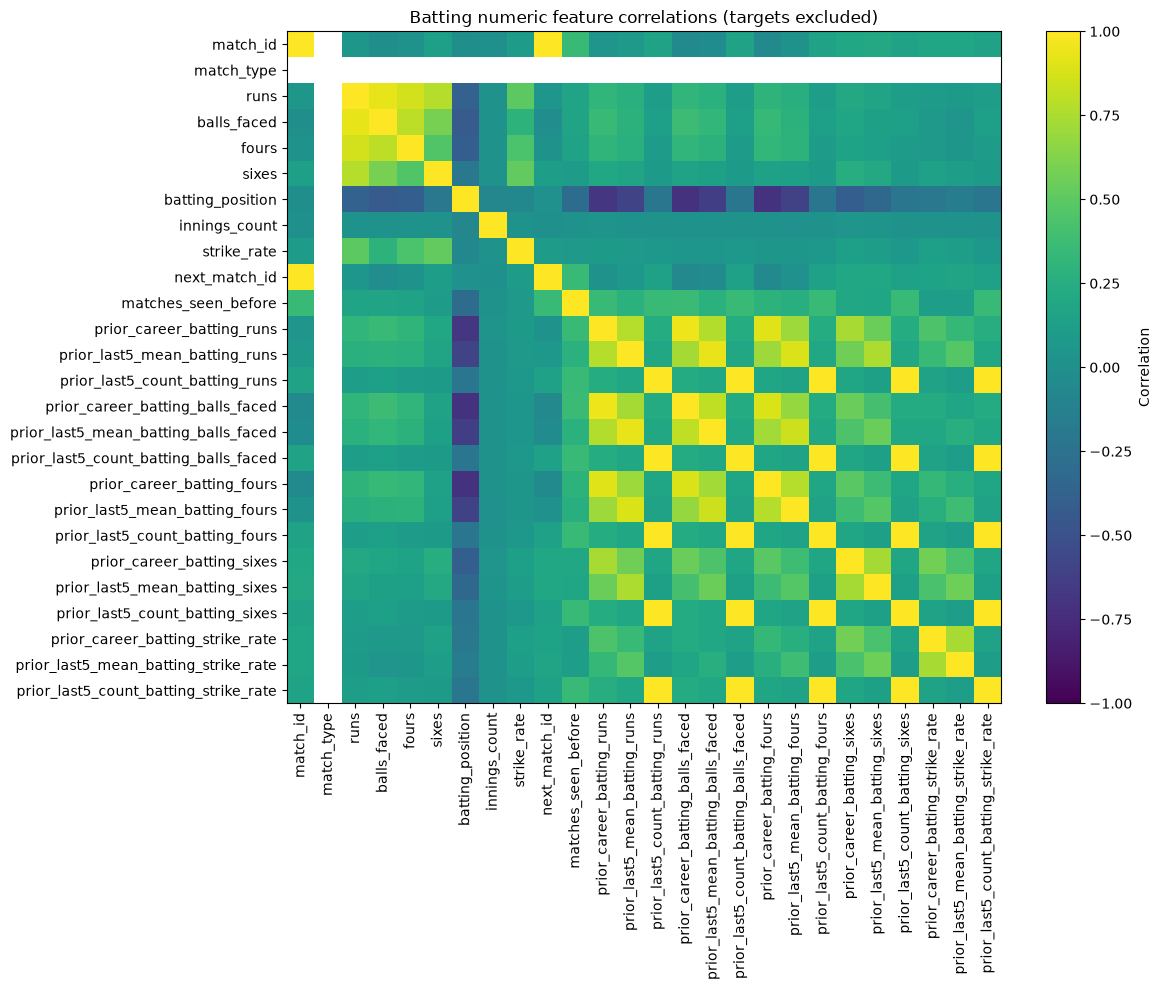

,match_id,match_type,legal_balls,runs_conceded,wickets,wides,noballs,dots,innings_count,overs,...,prior_last5_count_bowling_runs_conceded,prior_career_bowling_legal_balls,prior_last5_mean_bowling_legal_balls,prior_last5_count_bowling_legal_balls,prior_career_bowling_dots,prior_last5_mean_bowling_dots,prior_last5_count_bowling_dots,prior_career_bowling_economy,prior_last5_mean_bowling_economy,prior_last5_count_bowling_economy
match_id,1.000000,NaN,0.024942,0.174518,0.039031,0.044174,-0.016100,-0.064885,0.006360,0.024398,...,0.139633,0.062849,0.024951,0.139633,-0.054881,-0.099585,0.139633,0.243404,0.290936,0.139906
match_type,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
legal_balls,0.024942,NaN,1.000000,0.587238,0.387193,0.166281,0.054508,0.687585,0.071559,0.998634,...,0.076108,0.503767,0.491813,0.076108,0.457657,0.428516,0.076108,-0.189846,-0.175655,0.076402
runs_conceded,0.174518,NaN,0.587238,1.000000,0.034831,0.258340,0.152321,0.056784,0.045757,0.584468,...,0.045960,0.336799,0.322233,0.045960,0.284695,0.254106,0.045960,-0.004657,-0.000138,0.046234
wickets,0.039031,NaN,0.387193,0.034831,1.000000,0.072406,0.010245,0.502075,0.052123,0.384738,...,0.014318,0.179703,0.171165,0.014318,0.160000,0.147250,0.014318,-0.034943,-0.035189,0.014523
wides,0.044174,NaN,0.166281,0.258340,0.072406,1.000000,0.057221,0.130428,0.016478,0.164782,...,-0.014514,0.102748,0.100255,-0.014514,0.106943,0.102176,-0.014514,0.044350,0.039629,-0.014557
noballs,-0.016100,NaN,0.054508,0.152321,0.010245,0.057221,1.000000,0.035261,0.039003,0.052704,...,-0.024469,0.051865,0.043521,-0.024469,0.060992,0.061032,-0.024469,0.033396,0.015814,-0.024397
dots,-0.064885,NaN,0.687585,0.056784,0.502075,0.130428,0.035261,1.000000,0.044484,0.686400,...,0.040796,0.388388,0.376128,0.040796,0.423340,0.409954,0.040796,-0.161643,-0.160631,0.040977
innings_count,0.006360,NaN,0.071559,0.045757,0.052123,0.016478,0.039003,0.044484,1.000000,0.066342,...,-0.000725,0.031578,0.032904,-0.000725,0.029145,0.030206,-0.000725,-0.016562,-0.020405,-0.000711
overs,0.024398,NaN,0.998634,0.584468,0.384738,0.164782,0.052704,0.686400,0.066342,1.000000,...,0.075901,0.501150,0.489528,0.075901,0.455626,0.426826,0.075901,-0.190110,-0.176087,0.076190


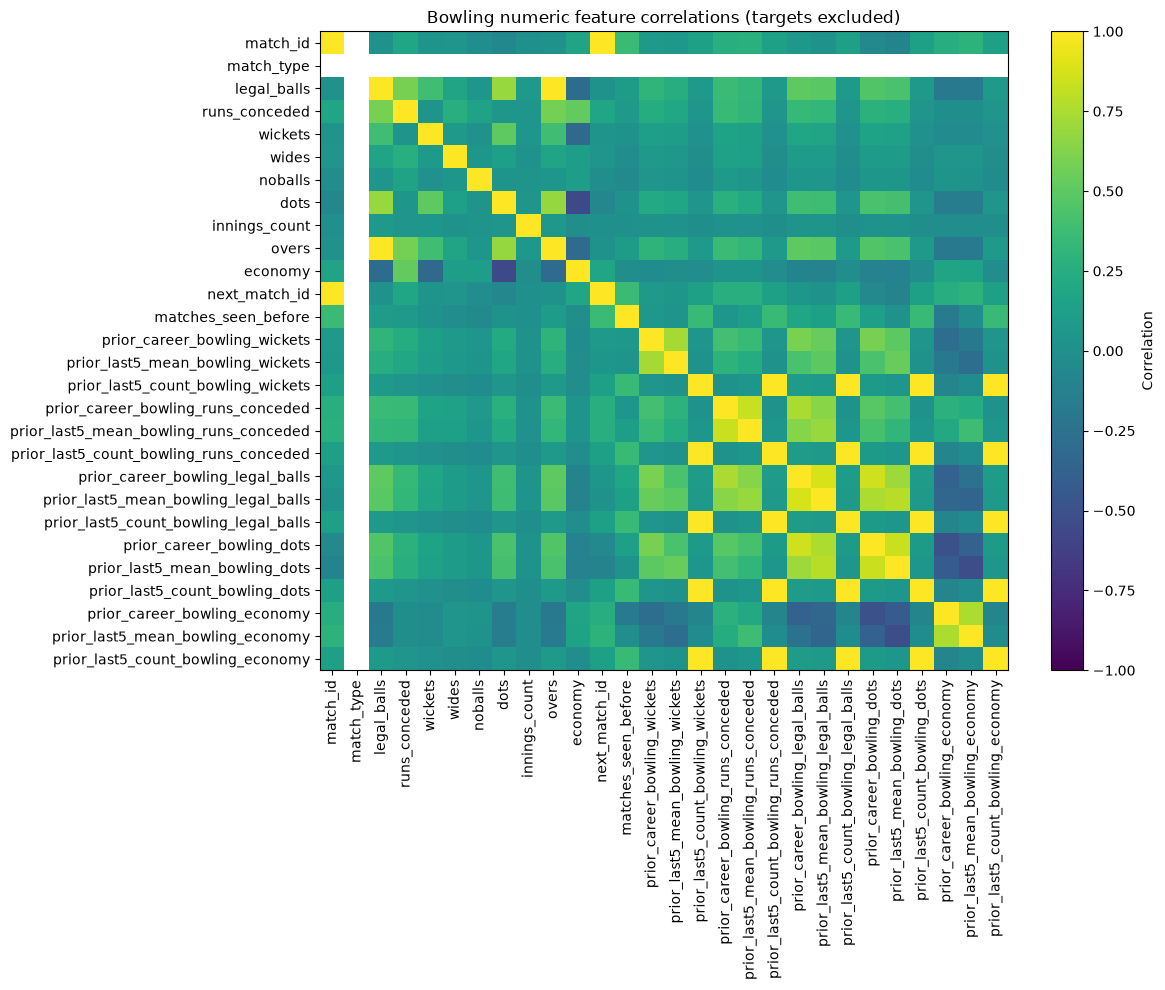

In [8]:
for name, df, target_cols in [
    ("batting", batting_features if batting_features is not None else batting, ["next_match_runs"]),
    ("bowling", bowling_features if bowling_features is not None else bowling,
     ["next_match_wickets", "next_match_runs_conceded"]),
]:
    numeric = df.select_dtypes(include=[np.number]).copy()
    numeric = numeric.drop(columns=[c for c in target_cols if c in numeric.columns], errors="ignore")
    if numeric.shape[1] < 2:
        print(f"{name}: fewer than two numeric non-target columns; correlation skipped.")
        continue
    corr = numeric.corr()
    display(corr)
    corr.to_csv(REPORTS_DIR / f"{name}_feature_correlations.csv")
    plt.figure(figsize=(min(12, 1 + len(corr.columns) * 0.7), min(10, 1 + len(corr.columns) * 0.6)))
    plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
    plt.colorbar(label="Correlation")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.index)), corr.index)
    plt.title(f"{name.title()} numeric feature correlations (targets excluded)")
    plt.tight_layout()
    plt.show()


## 7. Save EDA summary and documentation

This final section saves the main summary tables and writes a report. Read the generated tables and notebook plots before choosing model features or cleaning rules.


In [10]:

# Create a compact text report based on actual computed values.
report_lines = [
    "# Day 5: Exploratory Data Analysis",
    "",
    "## Dataset coverage",
    "",
    "```text",
    coverage_df.to_string(index=False),
    "```",
    "",
    "## Key observations to investigate",
    "- Review `missingness_report.csv` for columns with missing values.",
    "- Review `duplicate_key_report.csv` for repeated match/player keys.",
    "- Review `numeric_descriptive_statistics.csv` and boxplots for extreme values.",
    "- Review `target_summary.csv` if Day 4 target tables were available.",
    "- Do not remove outliers or impute missing values without a documented rule.",
    "",
    "## Outputs",
    "- `reports/day5/coverage_summary.csv`",
    "- `reports/day5/missingness_report.csv`",
    "- `reports/day5/duplicate_key_report.csv`",
    "- `reports/day5/numeric_descriptive_statistics.csv`",
    "- `reports/day5/target_summary.csv`",
    "",
    "## Limitations",
    "- Findings are descriptive and do not establish causality.",
    "- No model is trained on Day 5.",
    "- Verify suspected data-quality issues against source records before changing data.",
]

day5_report = "\n".join(report_lines)
day5_doc_path = DOCS_DIR / "day5_eda_and_data_quality.md"
day5_doc_path.write_text(day5_report, encoding="utf-8")

print("Saved documentation:", day5_doc_path)
print("EDA reports directory:", REPORTS_DIR)


Saved documentation: D:\Git\Personal\ipl-player-performance\docs\day5_eda_and_data_quality.md
EDA reports directory: D:\Git\Personal\ipl-player-performance\reports\day5
